# NBA Game Prediction: Exploratory Data Analysis

**Goal:** Understand what drives NBA game outcomes so we can build a model that predicts winners with 60%+ accuracy 

**Data:** Team-level game stats for three NBA regular seasons, one row per team per game (two rows per game).

**This notebook:** checks the data, explores how game stats relate to winning, tests home court advantage, and builds pre-game features from past games to avoid data leakage.

In [2]:
#import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
#import data
nba = pd.read_csv('../data/nba_games_cleaned.csv',parse_dates=['GAME_DATE'])
nba.head(3)

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,HOME_TEAM,OPPONENT
0,22023,1610612747,LAL,Los Angeles Lakers,22300061,2023-10-24,LAL @ DEN,L,240,41,...,44,23,5,4,12,18,107,-12,False,DEN
1,22023,1610612756,PHX,Phoenix Suns,22300062,2023-10-24,PHX @ GSW,W,240,42,...,60,23,5,7,19,22,108,4,False,GSW
2,22023,1610612743,DEN,Denver Nuggets,22300061,2023-10-24,DEN vs. LAL,W,240,48,...,42,29,9,6,12,15,119,12,True,LAL


In [62]:
#check everythings in line by looking at its shape
print(nba.shape)
print(nba.info())

(7380, 46)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7380 entries, 0 to 7379
Data columns (total 46 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   SEASON_ID          7380 non-null   int64         
 1   TEAM_ID            7380 non-null   int64         
 2   TEAM_ABBREVIATION  7380 non-null   object        
 3   TEAM_NAME          7380 non-null   object        
 4   GAME_ID            7380 non-null   int64         
 5   GAME_DATE          7380 non-null   datetime64[ns]
 6   MATCHUP            7380 non-null   object        
 7   WL                 7380 non-null   int64         
 8   MIN                7380 non-null   int64         
 9   FGM                7380 non-null   int64         
 10  FGA                7380 non-null   int64         
 11  FG_PCT             7380 non-null   float64       
 12  FG3M               7380 non-null   int64         
 13  FG3A               7380 non-null   int64         
 1

Everything looks about right except we need to make home team and WL ints so we can use it for plots and correlation.

In [4]:
# need to convert columns to ints
nba['WL'] = (nba['WL'] == 'W').astype(int)
nba['HOME_TEAM'] = (nba['HOME_TEAM']).astype(int)
nba.head()

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,HOME_TEAM,OPPONENT
0,22023,1610612747,LAL,Los Angeles Lakers,22300061,2023-10-24,LAL @ DEN,0,240,41,...,44,23,5,4,12,18,107,-12,0,DEN
1,22023,1610612756,PHX,Phoenix Suns,22300062,2023-10-24,PHX @ GSW,1,240,42,...,60,23,5,7,19,22,108,4,0,GSW
2,22023,1610612743,DEN,Denver Nuggets,22300061,2023-10-24,DEN vs. LAL,1,240,48,...,42,29,9,6,12,15,119,12,1,LAL
3,22023,1610612744,GSW,Golden State Warriors,22300062,2023-10-24,GSW vs. PHX,0,240,36,...,49,19,11,6,11,23,104,-4,1,PHX
4,22023,1610612766,CHA,Charlotte Hornets,22300063,2023-10-25,CHA vs. ATL,1,240,43,...,51,34,5,3,19,21,116,6,1,ATL


<Axes: >

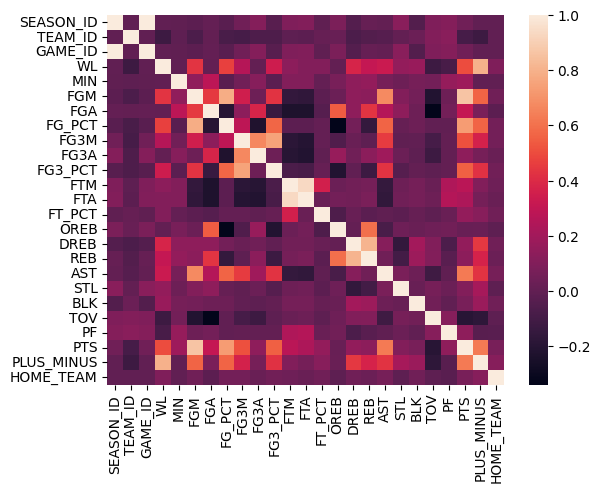

In [45]:
sns.heatmap(nba.corr(numeric_only=True))

**What the Heatmap shows:** From this we can see that the variables with the biggest correlation to winning are PLUS_MINUS, PTS, AST, REB, DREB, FG3_PCT, FG3M, FG_PCT, FGM. So I will look more into their relationships with winning first

<Axes: xlabel='PLUS_MINUS', ylabel='Count'>

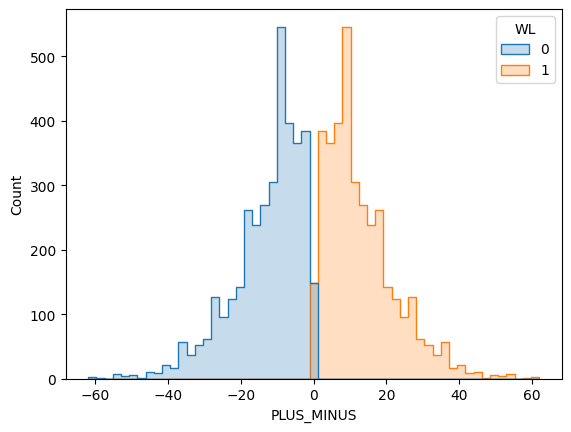

In [5]:
#plot showing relationship between WL and +/-
sns.histplot(x= 'PLUS_MINUS',data=nba,hue='WL' ,element='step')

**what the plot tells us:** This plot shows that plus or minus is always a win when its greater then 0 and a loss when less then 0. However it doesn't really have help us predict who wins because it's just the result of the game. Plus or minus just subtracts the number of points a team scored by how many points allowed.

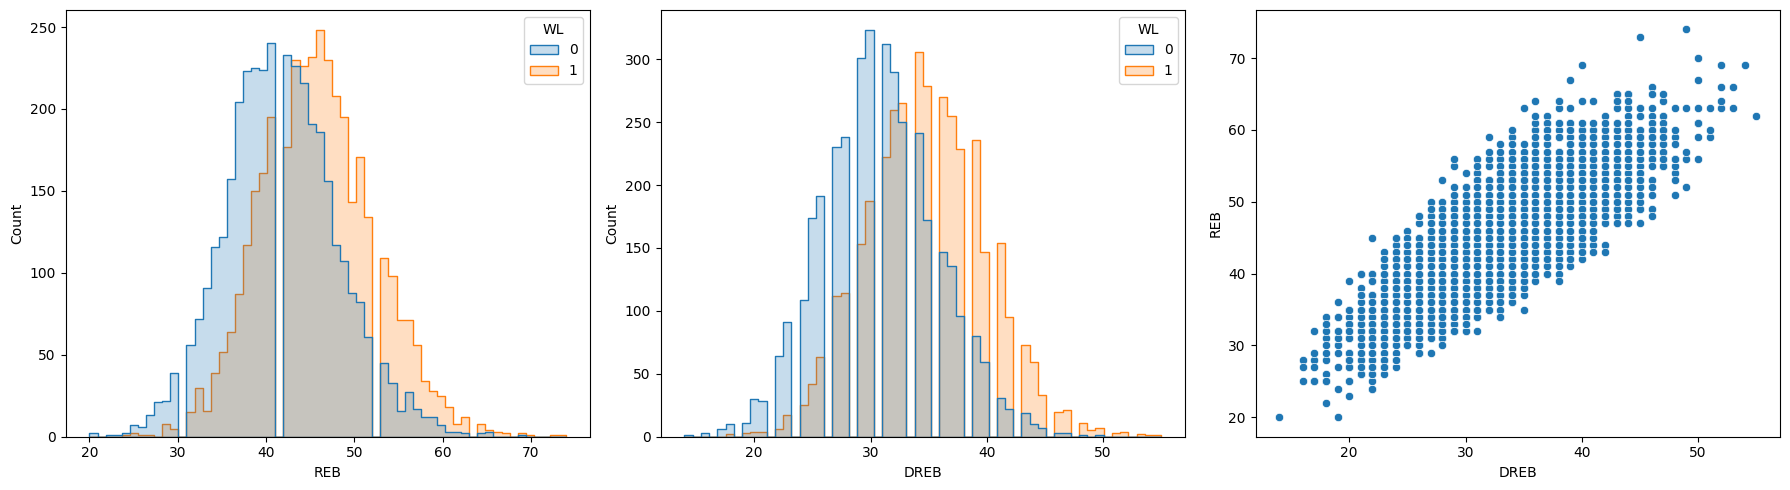

In [6]:
#plot showing REB and DREB
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.histplot(x= 'REB',data=nba,hue='WL' ,element='step',ax=axes[0])
sns.histplot(x= 'DREB',data=nba,hue='WL' ,element='step',ax=axes[1])
sns.scatterplot(x= 'DREB',y='REB',data=nba)
plt.tight_layout()

**What the plot tells us:** We can see that both DREB and REB plots shift the winning group to the right showing it does have a modest impact on winning outcome. However they're both heavily correlated, as we can see from the scatter plot and we likely won't need both. Looking at our heatmap it looks like DREB has a little more correlation according to the heatmap so we should use that and drop REB in preproccessing.

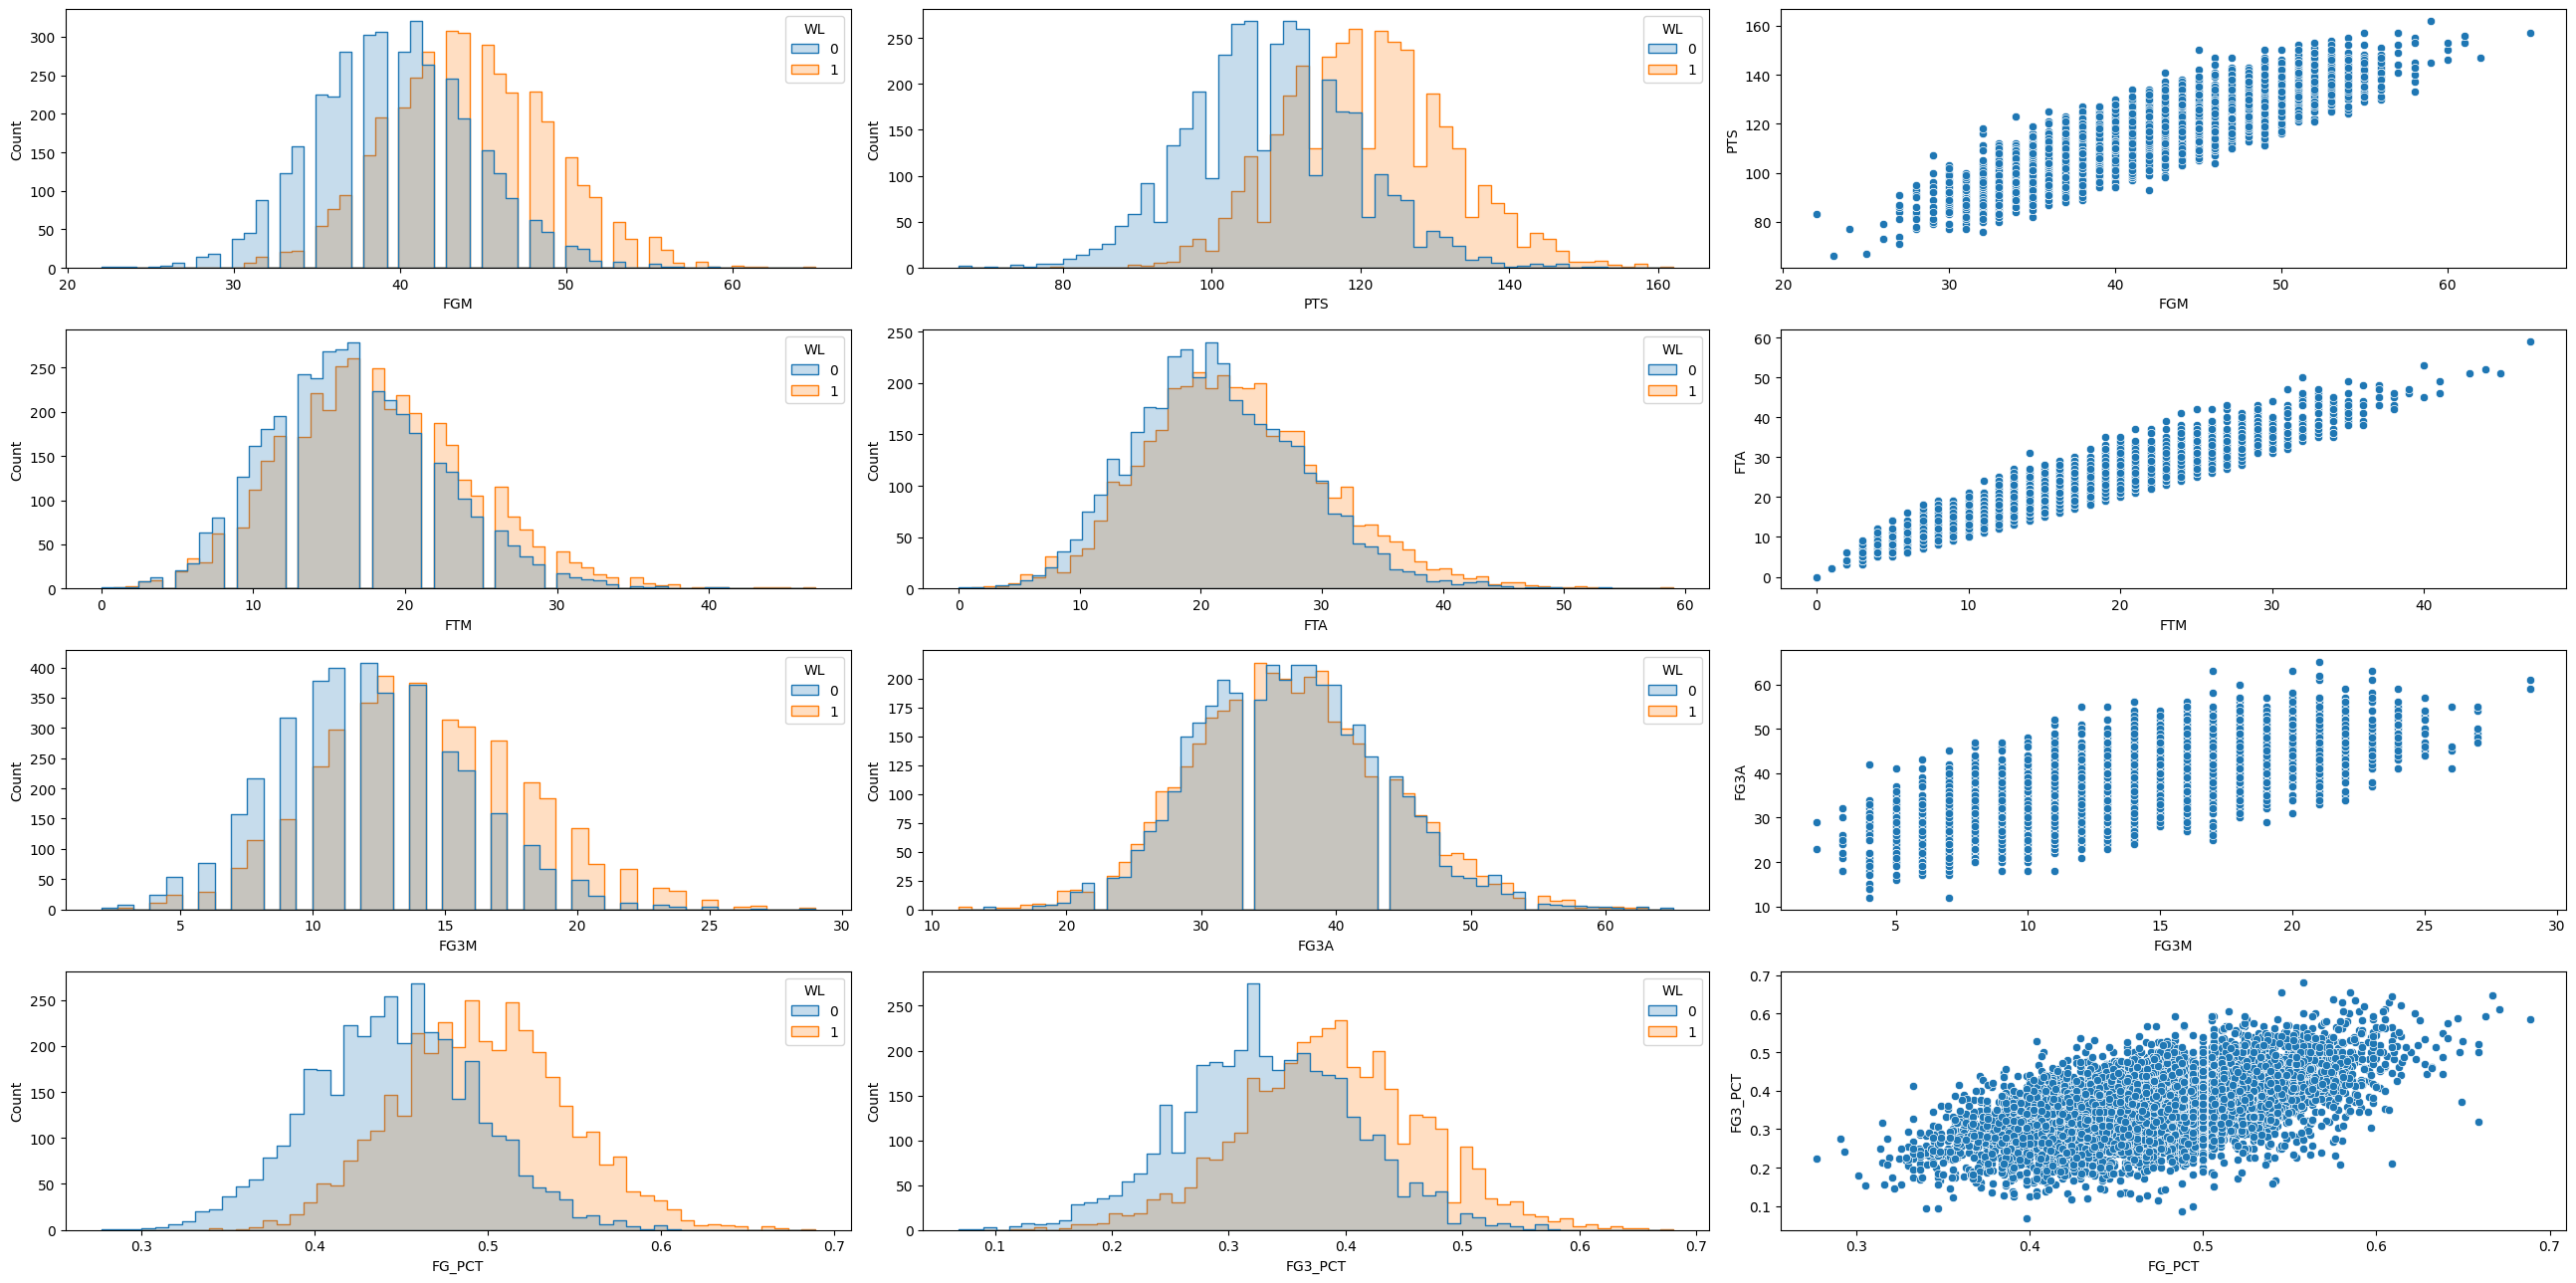

WL            1.000000e+00
PLUS_MINUS    8.000855e-01
PTS           5.009255e-01
FG_PCT        4.697759e-01
FGM           4.318088e-01
DREB          3.767681e-01
FG3_PCT       3.411766e-01
AST           3.264143e-01
REB           3.059359e-01
FG3M          2.608192e-01
BLK           1.706097e-01
STL           1.557738e-01
FTM           1.353110e-01
FTA           1.046188e-01
FT_PCT        1.029487e-01
HOME_TEAM     9.430929e-02
FG3A          5.786897e-03
FGA           4.920621e-03
OREB          4.868198e-03
GAME_ID       1.689289e-15
MIN          -9.459908e-17
SEASON_ID    -4.360874e-14
PF           -8.406106e-02
TEAM_ID      -1.194793e-01
TOV          -1.216745e-01
Name: WL, dtype: float64


In [8]:
#Do the same for other variables

#FGM PTS
fig, axes = plt.subplots(4,3,figsize=(26,13))
sns.histplot(x= 'FGM',data=nba,hue='WL' ,element='step',ax=axes[0,0])
sns.histplot(x= 'PTS',data=nba,hue='WL' ,element='step',ax=axes[0,1])
sns.scatterplot(x= 'FGM',y='PTS',data=nba,ax=axes[0,2])

#FTA FTM
sns.histplot(x= 'FTM',data=nba,hue='WL' ,element='step',ax=axes[1,0])
sns.histplot(x= 'FTA',data=nba,hue='WL' ,element='step',ax=axes[1,1])
sns.scatterplot(x= 'FTM',y='FTA',data=nba,ax=axes[1,2])

#FG3M FG3A
sns.histplot(x= 'FG3M',data=nba,hue='WL' ,element='step',ax=axes[2,0])
sns.histplot(x= 'FG3A',data=nba,hue='WL' ,element='step',ax=axes[2,1])
sns.scatterplot(x= 'FG3M',y='FG3A',data=nba,ax=axes[2,2])

#FG_PCT FG3_PCT
sns.histplot(x= 'FG_PCT',data=nba,hue='WL' ,element='step',ax=axes[3,0])
sns.histplot(x= 'FG3_PCT',data=nba,hue='WL' ,element='step',ax=axes[3,1])
sns.scatterplot(x= 'FG_PCT',y='FG3_PCT',data=nba,ax=axes[3,2])

plt.tight_layout()
plt.show()
#check the correlation rankings
print(nba.corr(numeric_only=True)['WL'].sort_values(ascending=False))

**What this plot shows** From this plot we can clearly see that points and field goals made clearly shifts the winnig group to the right by a pretty big amount. In comparison free throws made and freethrows attempted have little barely any impact at all on WL. We can tell because both Win and Loss groups overlap with a very tiny shift to the right by the winning group. Also FTM and FTA are heavily correlated as well as PTS and FGM which we can see from the scatterplot. Also FG3A had little to no correlation with WL which we see with both Win and Loss groups overlapping one another, however FG3M does. Lastly, FG_PCT and FG3_PCT Also have positive correlation to WL as well and are correlated with one another

<Axes: xlabel='TOV', ylabel='Count'>

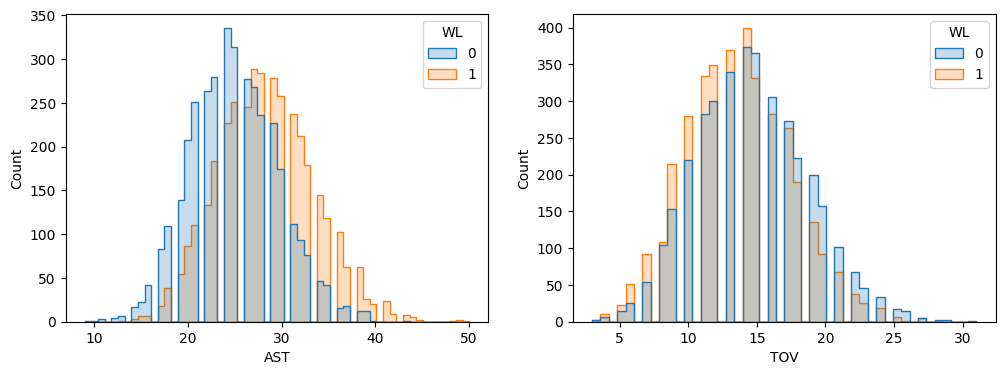

In [14]:
#Assist, turnovers
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(x= 'AST',data=nba,hue='WL' ,element='step',ax=axes[0])
sns.histplot(x= 'TOV',data=nba,hue='WL' ,element='step',ax=axes[1])


AST has positive corr with WL while TOV has slightly negative.

In [18]:
#Looking at home teams relationship with WL
nba.groupby('HOME_TEAM')['WL'].mean()

HOME_TEAM
0    0.452973
1    0.547283
Name: WL, dtype: float64

Home teams have a win rate 54% which is modest but real effect there. However we need to check if this was by chance or not. So we could check this with a hypothesis test

In [20]:
#Permutation 
nba['Permutation1'] = np.random.permutation(nba['WL'])
nba.groupby('HOME_TEAM')['Permutation1'].describe()

,count,mean,std,min,25%,50%,75%,max
HOME_TEAM,,,,,,,,
0,3700.0,0.505405,0.500038,0.0,0.0,1.0,1.0,1.0
1,3680.0,0.494565,0.500038,0.0,0.0,0.0,1.0,1.0


In this random shuffle home teams actually won less then away teams. We should conduct a for loop to continue this process and see if our original value was due to chance

In [61]:
#Hypothesis test 

#create a variable settling for home and away win records
home_wr = nba[nba['HOME_TEAM']==1]['WL'].mean()
away_wr = nba[nba['HOME_TEAM']==0]['WL'].mean()

#create variable for the observed diff of the data
obs_diff = home_wr - away_wr

#Make empty list for the permutation differences
diff = np.empty(10000)

#permutation test

for i in range(10000):
    nba['Permutation1'] = np.random.permutation(nba['WL'])
    means = nba.groupby('HOME_TEAM')['Permutation1'].mean()
    diff[i] = means[1] - means[0]
#Pvalues
p_val = np.sum(np.abs(diff) >= np.abs(obs_diff)) / len(diff)
print(p_val)

0.0


The pvalue is less than 0.0001 meaning the result we got was not by chance, showing that it's very unlikely our observed value was due to chance

Another key point we're missing is that this data mainly is regarding current games, not past games. We need to look at how past games and stats impact future games.

In [28]:
#Need to make the seaon values in order so that we can calculate the rolling stats
nba = nba.sort_values(['SEASON_ID', 'TEAM_ABBREVIATION', 'GAME_DATE'])
nba.head(3)

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,HOME_TEAM,OPPONENT,Permutation1
27,22023,1610612737,ATL,Atlanta Hawks,22300063,2023-10-25,ATL @ CHA,0,240,39,...,24,12,1,12,19,110,-6,0,CHA,0
43,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,240,42,...,28,7,6,14,20,120,-6,1,NYK,1
74,22023,1610612737,ATL,Atlanta Hawks,22300097,2023-10-29,ATL @ MIL,1,240,47,...,32,15,2,17,17,127,17,0,MIL,0


In [35]:
#make a column that tracks every teams win percentage throughout the season
nba['PRIOR_WIN_PCT'] = nba.groupby(['SEASON_ID','TEAM_ID'])['WL'].transform(lambda x: x.shift(1).expanding(min_periods=5).mean())

#Check its correlation with WL
nba[['PRIOR_WIN_PCT','WL']].corr()

,PRIOR_WIN_PCT,WL
PRIOR_WIN_PCT,1.000000,0.265718
WL,0.265718,1.000000


Looks like it does have a modest positive correlation on WL. We should also look at how opponents previous stats fair against corr

In [37]:
#grab the important stats 
stats = ['PTS', 'FG_PCT', 'FG3_PCT', 'DREB', 'AST', 'TOV']

#calculates average stats from past 10 games
for stat in stats:
    nba[stat + '_R10'] = nba.groupby(['SEASON_ID','TEAM_ID'])[stat].transform(lambda x: x.shift(1).rolling(10,min_periods=3).mean())

#sanity check
nba[(nba['TEAM_ABBREVIATION'] == 'ATL') & (nba['SEASON_ID'] == 22023)][['GAME_DATE', 'PTS', 'PTS_R10']].head(8)

,GAME_DATE,PTS,PTS_R10
27,2023-10-25,110,NaN
43,2023-10-27,120,NaN
74,2023-10-29,127,NaN
90,2023-10-30,127,119.000000
131,2023-11-01,130,121.000000
158,2023-11-04,123,122.800000
202,2023-11-06,117,122.833333
236,2023-11-09,120,122.000000


In [38]:
#time to make the opponent columns now
cols = ['PRIOR_WIN_PCT'] + [stat + '_R10' for stat in stats]

#seperate df for opponents stats
opp = nba[['GAME_ID', 'TEAM_ABBREVIATION'] + cols].copy()

#Renames columns to have opp in front of them so we can merge
opp.columns = ['GAME_ID', 'OPP'] + ['OPP_' + c for c in cols]

In [49]:
#Merge with nba
nba = nba.merge(opp, on=['GAME_ID', 'OPP'])

In [50]:
nba.head()

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,DREB_R10,AST_R10,TOV_R10,OPP_PRIOR_WIN_PCT,OPP_PTS_R10,OPP_FG_PCT_R10,OPP_FG3_PCT_R10,OPP_DREB_R10,OPP_AST_R10,OPP_TOV_R10
0,22023,1610612737,ATL,Atlanta Hawks,22300063,2023-10-25,ATL @ CHA,0,240,39,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,240,42,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22023,1610612737,ATL,Atlanta Hawks,22300097,2023-10-29,ATL @ MIL,1,240,47,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,240,48,...,32.666667,28.0,14.333333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,240,46,...,32.500000,28.0,13.500000,NaN,113.333333,0.445333,0.343,32.333333,26.0,13.666667


<Axes: >

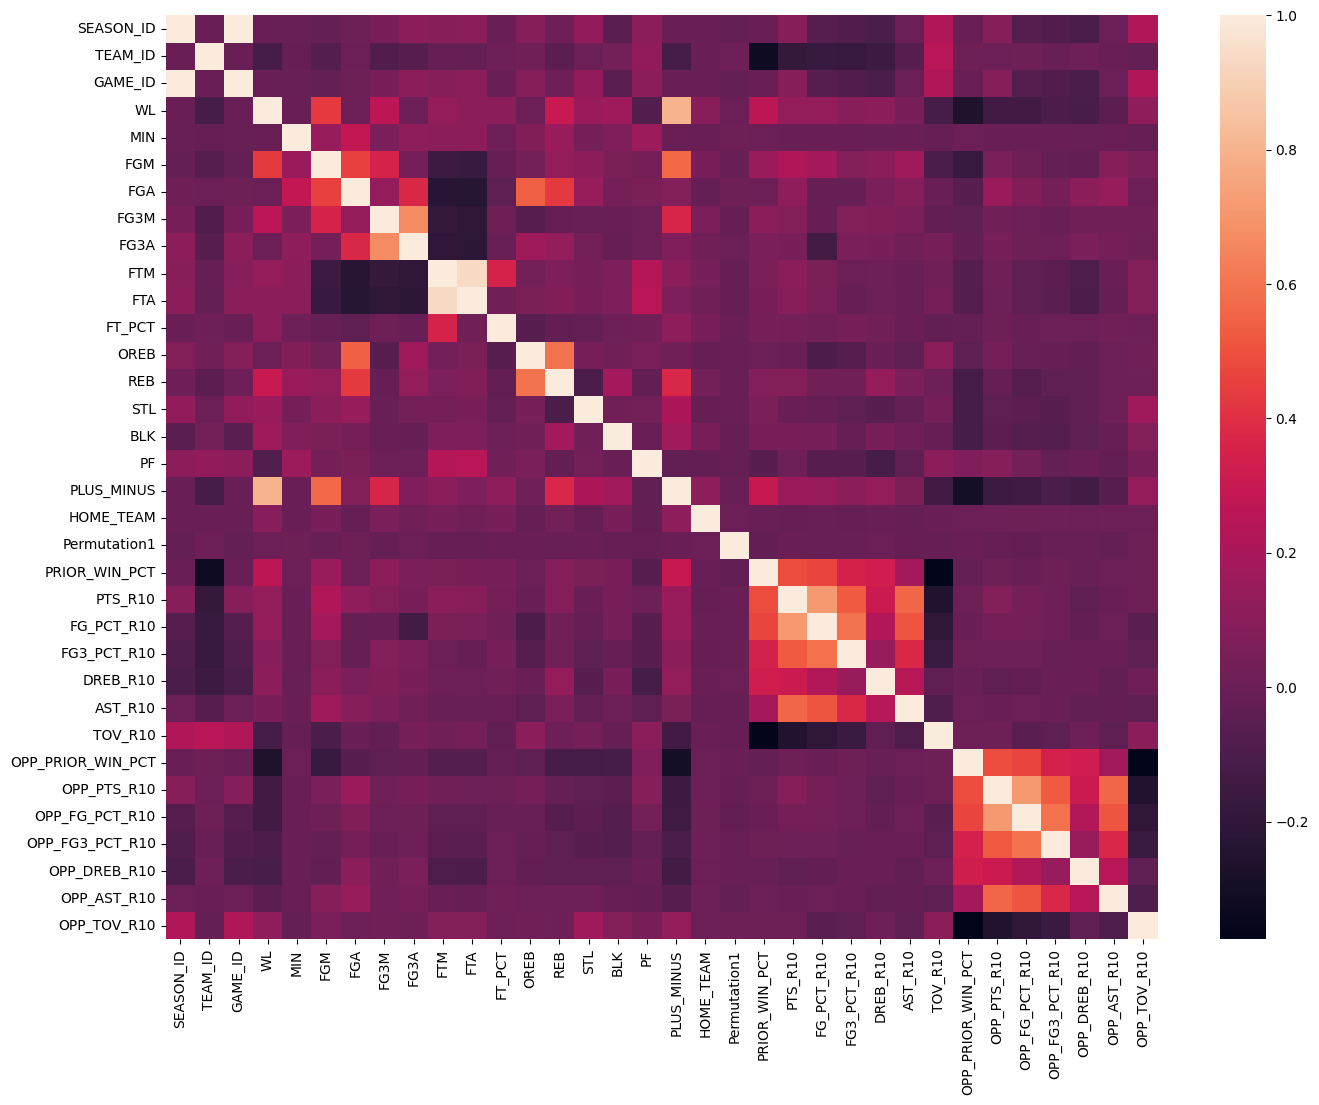

In [53]:
# Heatmap of correlation
plt.figure(figsize=(16, 12))
sns.heatmap(nba.drop(columns = stats).corr(numeric_only=True),xticklabels=True,yticklabels=True)

In [54]:
print(nba.corr(numeric_only=True)['WL'].sort_values(ascending=False))

WL                   1.000000e+00
PLUS_MINUS           8.000855e-01
PTS                  5.009255e-01
FG_PCT               4.697759e-01
FGM                  4.318088e-01
DREB                 3.767681e-01
FG3_PCT              3.411766e-01
AST                  3.264143e-01
REB                  3.059359e-01
PRIOR_WIN_PCT        2.657183e-01
FG3M                 2.608192e-01
BLK                  1.706097e-01
STL                  1.557738e-01
FG_PCT_R10           1.374336e-01
FTM                  1.353110e-01
PTS_R10              1.341964e-01
OPP_TOV_R10          1.225429e-01
DREB_R10             1.107314e-01
FTA                  1.046188e-01
FT_PCT               1.029487e-01
FG3_PCT_R10          9.615823e-02
HOME_TEAM            9.430929e-02
AST_R10              4.399193e-02
Permutation1         5.962060e-03
FG3A                 5.786897e-03
FGA                  4.920621e-03
OREB                 4.868198e-03
SEASON_ID            6.740902e-13
MIN                 -1.353348e-16
GAME_ID       

It does look like they play a factor on WL so we should look further into it

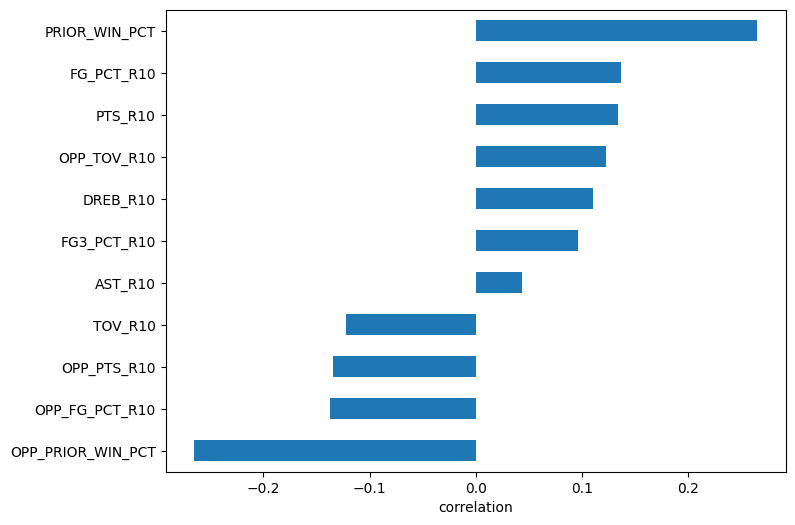

In [57]:
prior = ['PRIOR_WIN_PCT', 'OPP_PRIOR_WIN_PCT', 'FG_PCT_R10', 'PTS_R10', 'DREB_R10',
       'FG3_PCT_R10', 'AST_R10', 'TOV_R10', 'OPP_TOV_R10', 'OPP_PTS_R10', 'OPP_FG_PCT_R10']
nba[prior + ['WL']].corr()['WL'].drop('WL').sort_values().plot(kind='barh', figsize=(8, 6))
plt.xlabel('correlation')
plt.show()

From this we can see that teams previous stats have small positive imact on WL and OPP stats have small negative impact on WL. Both teams win percentage have the greatest impact on WL. Their identical on both ends because each game is repeated twice

<Axes: xlabel='DIFF_WIN_PCT', ylabel='Count'>

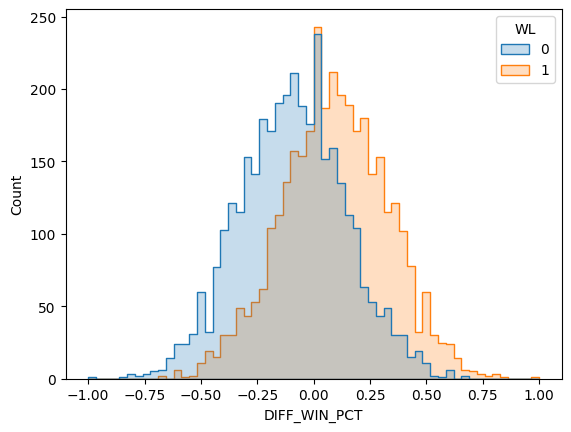

In [59]:
#Diff of Win %
nba['DIFF_WIN_PCT'] =  nba['PRIOR_WIN_PCT'] - nba['OPP_PRIOR_WIN_PCT']

sns.histplot(x='DIFF_WIN_PCT',data=nba,element='step',hue='WL')

This shows that teams who go into games having a higher win percentage tend to win more, shown by the orange shift to the right

## Summary of Findings

**Baseline:** Home teams win 54.7% of games (away teams 45.3%), and a permutation test showed this is very unlikely to be chance (p < 0.0001). Always picking the home team gives a 54.7% baseline accuracy, so the model needs to beat that. The 60% goal is about a 5 point improvement.

**Same-game stats:** Stats from the game itself relate strongly to winning: PTS (0.50), FG_PCT (0.47), FGM (0.43), DREB (0.38), FG3_PCT (0.34), and AST (0.33). PLUS_MINUS (0.80) is just the final margin, so they're not useful in actually predicting WL . Free throws, FG3A, FGA, and OREB showed little relationship with winning. REB and DREB overlap heavily, and so do FTM and FTA, PTS and FGM, and the made and attempted shot pairs.

**Pre-game features:** I built features from teams past games so we could actually have useful stats for predictions: season-to-date win percentage (PRIOR_WIN_PCT) and 10-game rolling averages of key stats, for both the team and its opponent. These have smaller correlations with winning than same-game stats, which is expected for pre-game information. PRIOR_WIN_PCT is the strongest (0.27), and teams with a better record than their opponent win more often, although the groups overlap a lot. The opponent features mirror the team's own (equal and opposite), because every game appears twice.

**Next steps (preprocessing and modeling):**
- Use only pre-game features: HOME_TEAM, PRIOR_WIN_PCT, the rolling stats, and their opponent versions.
- Drop same-game stats, PLUS_MINUS, REB, IDs, and text columns.
- Remove early-season rows with missing rolling values.
- Split the data by date (train on earlier games, test on later ones), not randomly.
- Compare models such as logistic regression and random forest against the 54.7% baseline.